# E001-GPU — CatBoost Baseline (Original Features, NVIDIA GPU)

**Goal:** Establish a trustworthy **ROC AUC** benchmark using the original fraud transaction columns, **before behavioral feature engineering**.

Data policy: use `train.csv` labels for training only; sort chronologically and reserve **January 30–February 5, 2026** as validation. The competition `test.csv` is not used in this notebook because its labels are unavailable. Later we will retrain on all labeled rows and create `submission.csv`.

**GPU variant:** The same data, feature choices, and chronological split as the CPU baseline. CatBoost GPU training needs an NVIDIA GPU and compatible driver; a separate CUDA Toolkit is normally not needed for the official Windows package. Run `nvidia-smi` to check GPU/driver before training. GPU scores may differ slightly from CPU scores.

**Learning checkpoints:** (1) understand splitting by time, (2) separate `X` and `y`, (3) prepare CatBoost categorical variables, (4) train with Logloss, (5) evaluate with ROC AUC.

## 1 — Imports and dataset loading

`Path.cwd()` tells us where Jupyter is running; VS Code may run from the repository root or the `notebooks/` folder. We therefore look for `data/train.csv` in both locations. `pd.read_csv()` loads a CSV into a DataFrame.

In [2]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score, roc_curve

working_dir = Path.cwd()
candidate_data_dirs = [
    working_dir / "data",            # Notebook launched from repo root
    working_dir.parent / "data",     # Notebook launched from notebooks/
]
data_dir = next(
    (folder for folder in candidate_data_dirs if (folder / "train.csv").exists()),
    None,
)
if data_dir is None:
    raise FileNotFoundError(
        "Could not locate data/train.csv. Open the repository in VS Code "
        "and put train.csv inside its data folder."
    )

project_root = data_dir.parent
train = pd.read_csv(data_dir / "train.csv")

# Training timestamps are ISO-like; the competition test file has a different format.
train["timestamp"] = pd.to_datetime(
    train["timestamp"], format="%Y-%m-%d %H:%M:%S"
)

print("Project:", project_root)
print("Train shape:", train.shape)
print("Fraud count:", train["is_fraud"].sum())
print("Fraud rate:", f"{train['is_fraud'].mean():.2%}")
print("Date range:", train["timestamp"].min(), "→", train["timestamp"].max())
display(train.head(3))

Project: c:\Users\acer\Desktop\Dabpe\DADS\Fraud-Detection-CatBoost
Train shape: (60197, 20)
Fraud count: 799
Fraud rate: 1.33%
Date range: 2026-01-01 00:07:15 → 2026-02-05 23:59:19


,transaction_id,timestamp,card_id,card_holder,customer_age,customer_home_country,account_age_days,amount,merchant_id,merchant_name,merchant_category,merchant_country,is_foreign_merchant,channel,card_present,device_id,ip_address,ip_country,is_foreign_ip,is_fraud
0,TXN_000001,2026-01-01 00:07:15,C03949,Frau Krystyna Fliegner MBA.,50,NL,682,171.70,M00042,Nogueira Sá e Filhos,gambling,NL,0,in_store,True,NaN,72.164.29.89,NL,0,0
1,TXN_000002,2026-01-01 00:34:05,C02996,Dipl.-Ing. Cemil Lübs,22,DE,842,248.09,M00532,Small-Anderson,travel,DE,0,recurring,False,NaN,12.5.250.227,DE,0,0
2,TXN_000003,2026-01-01 01:00:23,C06754,Scott Turner,53,IT,111,305.51,M00800,Kreusel,travel,IT,0,in_store,True,NaN,22.113.42.172,IT,0,0


## 2 — Time-based validation split

For a fair local test, pretend that we are standing at the end of **January 29** and trying to predict later transactions. We reserve complete days **January 30–February 5** for validation. This mirrors the real train-then-future-test setup more closely than a shuffled random split.

**Critical:** Do not choose or change the split after inspecting its labels to maximize AUC.

In [3]:
# Put transactions into chronological order.
train = train.sort_values("timestamp", kind="stable").reset_index(drop=True)

validation_start = pd.Timestamp("2026-01-30")
train_part = train.loc[train["timestamp"] < validation_start].copy()
valid_part = train.loc[train["timestamp"] >= validation_start].copy()

assert train_part["timestamp"].max() < valid_part["timestamp"].min()
assert len(train_part) + len(valid_part) == len(train)
assert train_part["is_fraud"].nunique() == 2
assert valid_part["is_fraud"].nunique() == 2

summary = pd.DataFrame({
    "rows": [len(train_part), len(valid_part)],
    "frauds": [train_part["is_fraud"].sum(), valid_part["is_fraud"].sum()],
    "fraud_rate": [train_part["is_fraud"].mean(), valid_part["is_fraud"].mean()],
    "first_timestamp": [train_part["timestamp"].min(), valid_part["timestamp"].min()],
    "last_timestamp": [train_part["timestamp"].max(), valid_part["timestamp"].max()],
}, index=["Train (past)", "Validation (future)"])
display(summary)

print("Validation fraction:", f"{len(valid_part)/len(train):.1%}")

,rows,frauds,fraud_rate,first_timestamp,last_timestamp
Train (past),48402,625,0.012913,2026-01-01 00:07:15,2026-01-29 23:59:57
Validation (future),11795,174,0.014752,2026-01-30 00:04:48,2026-02-05 23:59:19


Validation fraction: 19.6%


## 3 — Choose original features; no engineering yet

Remove:
- `is_fraud`: this is the **target**, never a feature.
- `transaction_id`: unique identifier with no declared predictive signal.
- `timestamp`: used for ordering; we intentionally do **not** derive hour/day features in E001.
- `card_holder`, `merchant_name`: decorative Faker text.
- `ip_address`: anonymized and essentially unique; use `ip_country` instead.

Retain original numerical and categorical transaction fields, including `card_id`, `merchant_id`, and `device_id`. CatBoost accepts categorical strings. Missing `device_id` is expected for offline/recurring transactions; fill only that missing categorical value with a placeholder. Converting a boolean column to 0/1 is **preprocessing**, not an engineered behavioral feature.

In [4]:
exclude_columns = [
    "transaction_id", "timestamp", "card_holder", "merchant_name",
    "ip_address", "is_fraud",
]
feature_columns = [col for col in train.columns if col not in exclude_columns]

X_train = train_part[feature_columns].copy()
X_valid = valid_part[feature_columns].copy()
y_train = train_part["is_fraud"]
y_valid = valid_part["is_fraud"]

# Convert Boolean to numeric (0 or 1).
for frame in (X_train, X_valid):
    frame["card_present"] = frame["card_present"].astype("int8")

# Find all string categorical features (card_id, merchant_id, device_id, etc.).
cat_features = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

# CatBoost does not accept NaN as a categorical value; mark missing devices explicitly.
for frame in (X_train, X_valid):
    frame[cat_features] = frame[cat_features].fillna("__MISSING__").astype(str)

print(f"Input feature count: {len(feature_columns)}")
print("Categorical features:", cat_features)
print("Numerical features:", [c for c in feature_columns if c not in cat_features])
assert X_train.columns.tolist() == X_valid.columns.tolist()
assert X_train[cat_features].isna().sum().sum() == 0
assert "is_fraud" not in X_train.columns

Input feature count: 14
Categorical features: ['card_id', 'customer_home_country', 'merchant_id', 'merchant_category', 'merchant_country', 'channel', 'device_id', 'ip_country']
Numerical features: ['customer_age', 'account_age_days', 'amount', 'is_foreign_merchant', 'card_present', 'is_foreign_ip']


## GPU preflight — Check NVIDIA driver and device

`nvidia-smi` reports the installed NVIDIA GPU, driver and available memory. If it is missing or fails, check the NVIDIA driver and that your notebook is running on the local Windows machine.


In [5]:
import shutil
import subprocess
import catboost

print('CatBoost version:', catboost.__version__)
if shutil.which('nvidia-smi'):
    gpu_check = subprocess.run(
        ['nvidia-smi'], capture_output=True, text=True, check=False
    )
    print(gpu_check.stdout if gpu_check.returncode == 0 else gpu_check.stderr)
else:
    print('nvidia-smi not found on PATH. Check your NVIDIA graphics driver.')


CatBoost version: 1.2.10
Sat Nov 14 23:21:54 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 581.08                 Driver Version: 581.08         CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3070 ...  WDDM  |   00000000:01:00.0 Off |                  N/A |
| N/A   40C    P8             12W /   85W |     139MiB /   8192MiB |      0%      Default |
|                                         |                        |                  N/A |
+----------------------

## 4 — Train CatBoost

`loss_function="Logloss"` tells CatBoost what to minimize during training; `eval_metric="AUC"` monitors the ranking quality on our later validation period. `eval_set` is used for early stopping and choosing the best iteration, **not for fitting fraud labels directly as extra training samples**.

We specify a fixed `random_seed` for reproducibility. This is a **starting configuration**, not a claim that these hyperparameters are optimal.
**GPU:** `task_type="GPU"` and `devices="0"` enable NVIDIA GPU training. If it fails with a CUDA/driver error, check the driver or try `task_type="CPU"` for comparison.


In [6]:
model = CatBoostClassifier(
    iterations=600,             # Maximum number of boosting trees
    depth=6,                    # Levels in each symmetric tree
    learning_rate=0.05,         # Shrink each new tree's contribution
    l2_leaf_reg=3.0,            # Regularization for leaf estimates
    loss_function="Logloss",    # Training objective
    eval_metric="AUC",          # Selection/evaluation metric
    task_type="GPU",           # Train with NVIDIA GPU
    devices="0",              # Use the first NVIDIA GPU
    random_seed=42,
    verbose=100,
    allow_writing_files=False,  # No catboost_info/ log directory
)

model.fit(
    X_train,
    y_train,
    cat_features=cat_features,
    eval_set=(X_valid, y_valid),
    early_stopping_rounds=70,
    use_best_model=True,
)

print("Training device:", model.get_param("task_type"))
print("Best iteration:", model.best_iteration_)

Default metric period is 5 because AUC is/are not implemented for GPU


0:	test: 0.5902923	best: 0.5902923 (0)	total: 61.7ms	remaining: 37s
bestTest = 0.8868262172
bestIteration = 15
Shrink model to first 16 iterations.
Training device: GPU
Best iteration: 15


## 5 — Evaluate ROC AUC on unseen validation dates

`predict_proba(X_valid)` returns two columns: probability of class 0 and probability of class 1. Selecting `[:, 1]` means **probability of fraud**. `roc_auc_score()` measures how well those probabilities rank labeled fraud above labeled legitimate transactions across thresholds.

**Never use `.predict()` to calculate our main competition score:** `.predict()` converts probabilities to discrete class predictions.

E001 validation ROC AUC: 0.8868
Probability range: 0.025199266497103263 to 0.5662938195941051


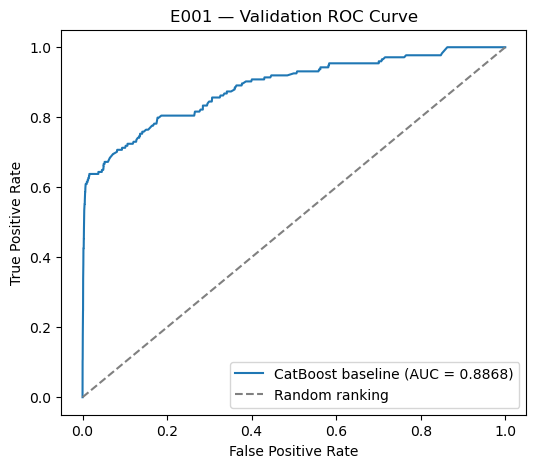

In [7]:
valid_probabilities = model.predict_proba(X_valid)[:, 1]
valid_auc = roc_auc_score(y_valid, valid_probabilities)

print(f"E001 validation ROC AUC: {valid_auc:.4f}")
print("Probability range:", valid_probabilities.min(), "to", valid_probabilities.max())

fpr, tpr, thresholds = roc_curve(y_valid, valid_probabilities)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, label=f"CatBoost baseline (AUC = {valid_auc:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random ranking")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="E001 — Validation ROC Curve")
ax.legend(loc="lower right")
plt.show()

## 6 — Interpret the baseline and record the experiment

Feature importance is a **diagnostic**, not automatic proof that a feature should be dropped. We will next add groups of engineered features one at a time and re-evaluate using the **same validation period**.

Avoid making many decisions using a single holdout; we can later confirm promising changes on multiple forward-time validation windows.

In [8]:
importance = (
    pd.DataFrame({
        "feature": feature_columns,
        "importance": model.get_feature_importance(),
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)
display(importance.head(15))

print("Record in experiments/results.csv:")
print({
    "experiment_id": "E001-GPU",
    "model": "CatBoostClassifier",
    "features": "original selected columns (no engineered features)",
    "validation_method": "chronological holdout: 2026-01-30 onwards",
    "roc_auc": round(valid_auc, 6),
    "notes": "NVIDIA GPU, Logloss, AUC early stopping, seed 42",
})

,feature,importance
0,amount,38.907726
1,merchant_id,22.086670
2,merchant_category,17.834309
3,is_foreign_merchant,10.243334
4,channel,5.478792
5,is_foreign_ip,2.343644
6,ip_country,1.531611
7,customer_home_country,0.691147
8,merchant_country,0.676093
9,account_age_days,0.206675


Record in experiments/results.csv:
{'experiment_id': 'E001-GPU', 'model': 'CatBoostClassifier', 'features': 'original selected columns (no engineered features)', 'validation_method': 'chronological holdout: 2026-01-30 onwards', 'roc_auc': 0.886826, 'notes': 'NVIDIA GPU, Logloss, AUC early stopping, seed 42'}


## Checkpoint — Answer before moving to E002

1. Why do we split by time rather than randomly for this competition?
2. Why is `device_id` missingness encoded as a string placeholder instead of filling it with numerical zero?
3. Why do we use `model.predict_proba(X_valid)[:, 1]` for ROC AUC?
4. Which original feature has the highest importance? Is that evidence of causality?

**Next experiment:** build customer spending features (card median amount, spending ratio), then compare E002 to E001 under exactly the same time-based split.

**Submission is intentionally deferred:** only after selecting and validating a model should we refit it on all 60,197 labeled transactions and score the 39,803 unlabeled competition test rows.

## E001-B — Expanding-Window Time-Series Cross-Validation

### Objective

Evaluate the stability and generalization performance of our baseline CatBoost fraud detection model across multiple chronological validation periods.

In Experiment E001-A, we used a single time-based holdout (January 30 – February 5, 2026) and obtained:

**Validation ROC AUC = 0.8868**

Although this result indicates promising classification performance, a single holdout may not fully represent the model's performance across different time periods.

Therefore, we introduce **Expanding-Window Cross-Validation** to obtain a more robust estimate of model performance.

### Why Time-Based Cross-Validation?

Our dataset contains transactions ordered chronologically, and the competition's unseen test dataset covers a later period.

Unlike ordinary shuffled Stratified K-Fold, time-based validation ensures that:

- The model trains on earlier transactions.
- The model is evaluated on later transactions.
- Future fraud labels are not used to train models evaluated on earlier periods.
- Model performance is measured across multiple time windows.

### Cross-Validation Design

We use three expanding-window folds:

| Fold | Training period | Validation period |
|---|---|---|
| 1 | Jan 1–18, 2026 | Jan 19–24, 2026 |
| 2 | Jan 1–24, 2026 | Jan 25–30, 2026 |
| 3 | Jan 1–30, 2026 | Jan 31–Feb 5, 2026 |

The training window expands with each fold, while the validation window moves forward in time.

A separate CatBoost model is trained from scratch for each fold using the same original features and hyperparameters as E001-A.

### Model Configuration

- **Algorithm:** CatBoostClassifier
- **Device:** NVIDIA GPU
- **Iterations:** 600 maximum
- **Tree depth:** 6
- **Learning rate:** 0.05
- **L2 regularization:** 3.0
- **Training loss:** Logloss (Binary Cross-Entropy)
- **Evaluation metric:** ROC AUC
- **Early stopping:** 70 rounds without improvement

No additional behavioral feature engineering is applied in this experiment.

### Evaluation

For each fold, we calculate:

\[
AUC_k=\operatorname{ROC\_AUC}(y_{\text{valid},k},\hat{p}_{\text{valid},k})
\]

We summarize performance using:

\[
\text{Mean AUC}=\frac{1}{K}\sum_{k=1}^{K}AUC_k
\]

We also calculate the standard deviation of the fold AUC scores to examine variation between validation periods.

**Interpretation:**

- Higher mean ROC AUC indicates better average discrimination between fraudulent and legitimate transactions.
- Lower AUC variation suggests more consistent performance across the evaluated periods.
- Large differences between folds may indicate temporal distribution changes, small fraud sample counts, or model instability.

Because the same validation data is used for early stopping, these scores are development estimates rather than independent final test results.

### Expected Outcome

Establish a reproducible cross-validation benchmark that will be used to evaluate subsequent feature engineering and model optimization experiments.

The validation folds and preprocessing strategy should remain consistent when comparing future experiments.

In [9]:
import numpy as np
import pandas as pd

from catboost import CatBoostClassifier
from sklearn.metrics import roc_auc_score

# Define expanding-window validation periods
time_folds = [
    ("2026-01-19", "2026-01-25"),
    ("2026-01-25", "2026-01-31"),
    ("2026-01-31", "2026-02-06"),
]

cv_results = []

for fold_number, (start, end) in enumerate(time_folds, start=1):

    # Step 1: Define chronological splits
    start_date = pd.Timestamp(start)
    end_date = pd.Timestamp(end)

    train_mask = train["timestamp"] < start_date

    valid_mask = (
        (train["timestamp"] >= start_date)
        & (train["timestamp"] < end_date)
    )

    # Step 2: Separate features and labels
    X_fold_train = train.loc[train_mask, feature_columns].copy()
    X_fold_valid = train.loc[valid_mask, feature_columns].copy()

    y_fold_train = train.loc[train_mask, "is_fraud"]
    y_fold_valid = train.loc[valid_mask, "is_fraud"]

    assert y_fold_train.nunique() == 2
    assert y_fold_valid.nunique() == 2

    # Step 3: Apply the same preprocessing as E001-A
    for frame in (X_fold_train, X_fold_valid):
        frame["card_present"] = frame["card_present"].astype("int8")
        frame[cat_features] = (
            frame[cat_features]
            .fillna("__MISSING__")
            .astype(str)
        )

    # Step 4: Train a fresh model for each fold
    fold_model = CatBoostClassifier(
        iterations=600,
        depth=6,
        learning_rate=0.05,
        l2_leaf_reg=3.0,
        loss_function="Logloss",
        eval_metric="AUC",
        task_type="GPU",
        devices="0",
        random_seed=42,
        verbose=False,
        allow_writing_files=False,
    )

    fold_model.fit(
        X_fold_train,
        y_fold_train,
        cat_features=cat_features,
        eval_set=(X_fold_valid, y_fold_valid),
        early_stopping_rounds=70,
        use_best_model=True,
    )

    # Step 5: Evaluate
    probabilities = fold_model.predict_proba(X_fold_valid)[:, 1]
    auc = roc_auc_score(y_fold_valid, probabilities)

    cv_results.append({
        "fold": fold_number,
        "train_rows": len(X_fold_train),
        "valid_rows": len(X_fold_valid),
        "valid_frauds": int(y_fold_valid.sum()),
        "roc_auc": auc,
        "best_iteration": fold_model.best_iteration_,
    })

    print(f"Fold {fold_number}: ROC AUC = {auc:.4f}")

# Summarize cross-validation
results_df = pd.DataFrame(cv_results)

display(results_df)

print(f"Mean ROC AUC: {results_df['roc_auc'].mean():.4f}")
print(f"Std ROC AUC: {results_df['roc_auc'].std():.4f}")

Default metric period is 5 because AUC is/are not implemented for GPU


Fold 1: ROC AUC = 0.8868


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 2: ROC AUC = 0.8375


Default metric period is 5 because AUC is/are not implemented for GPU


Fold 3: ROC AUC = 0.8984


,fold,train_rows,valid_rows,valid_frauds,roc_auc,best_iteration
0,1,29618,10336,140,0.886803,90
1,2,39954,10263,94,0.837461,16
2,3,50217,9980,156,0.898440,14


Mean ROC AUC: 0.8742
Std ROC AUC: 0.0324
